## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов. 

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК. 

После жесткого дедлайна работы не принимаются. 

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [3]:
df = pd.read_csv('final_project_delivery.csv')

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.00,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.90,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.80,no,iOS,Baixa,5203,returning


Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы / Все заказы), Cancellation Rate (Отмененные заказы / Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

In [79]:
def get_line_plot(df, x, y, title, annotate=False):
    fig, ax1 = plt.subplots(figsize=(12,6))
    
    if len(y) == 2:
        ax1.plot(df[x], df[y[0]], label=y[0], color='blue')
        ax1.set_ylabel(y[0])

        plt.xticks(rotation=45)

        if annotate:
            for i, val in enumerate(df[y[0]]):
                ax1.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        ax2 = ax1.twinx()
        ax2.plot(df[x], df[y[1]], label=y[1], color='green')
        ax2.set_ylabel(f'{y[1]}')
        ax2.tick_params(axis='y')

        if annotate:
            for i, val in enumerate(df[y[1]]):
                ax2.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2,
                   loc='center left', bbox_to_anchor=(1.05, 0.8))

        ax1.grid(True, which='both')
        fig.suptitle(title)
        fig.tight_layout()
        
        return plt.show()

    else:
        for col in y:
            plt.plot(df[x], df[col], label=col, color='blue')

            if annotate:
                for i, val in enumerate(df[col]):
                    plt.text(df[x].iloc[i], val, f'{val:.2f}', fontsize=9)

        plt.title(title)
        plt.xlabel('Date')
        plt.ylabel('Metric Value')
        plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.8))
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()

    return plt.show()
def get_several_lines_plot(df, x, y_list, title):
    plt.figure(figsize=(12,6))
    colors = ['green', 'blue', 'orange', 'pink', 'violet']
    
    for i, col in enumerate(y_list):
        if x == 'date':
            x_axis = df[x]
        else:
            x_axis = df[x].astype(str)

        y_axis = df[col]
        plt.plot(x_axis, y_axis, label=col, color=colors[i])

        for xi, yi in zip(x_axis, y_axis):
            plt.text(xi, yi, f'{yi:.2f}', fontsize=9, ha='center', va='bottom')

    plt.title(title)
    plt.xlabel('Date')
    plt.xticks(rotation=45)
    plt.ylabel('Metric Value')
    
    plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.9))
    
    plt.grid(True)
    plt.tight_layout()
    plt.show()



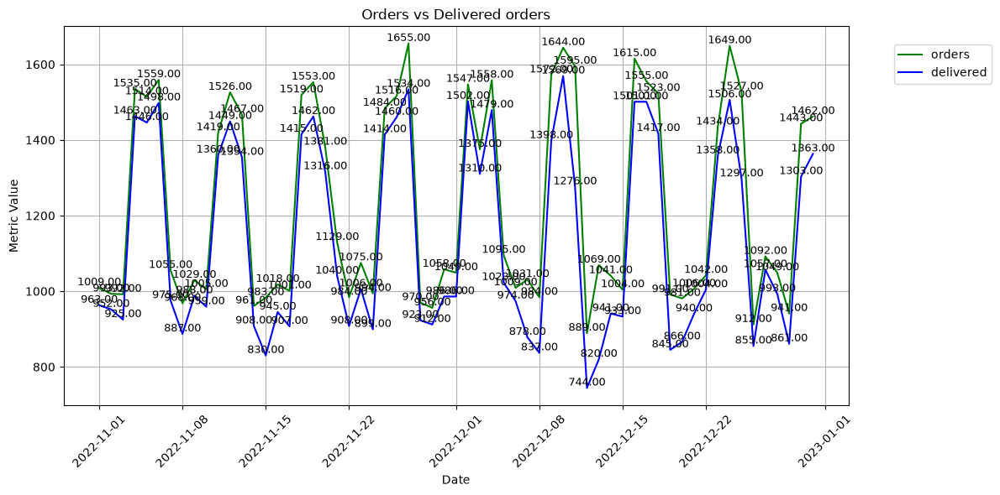

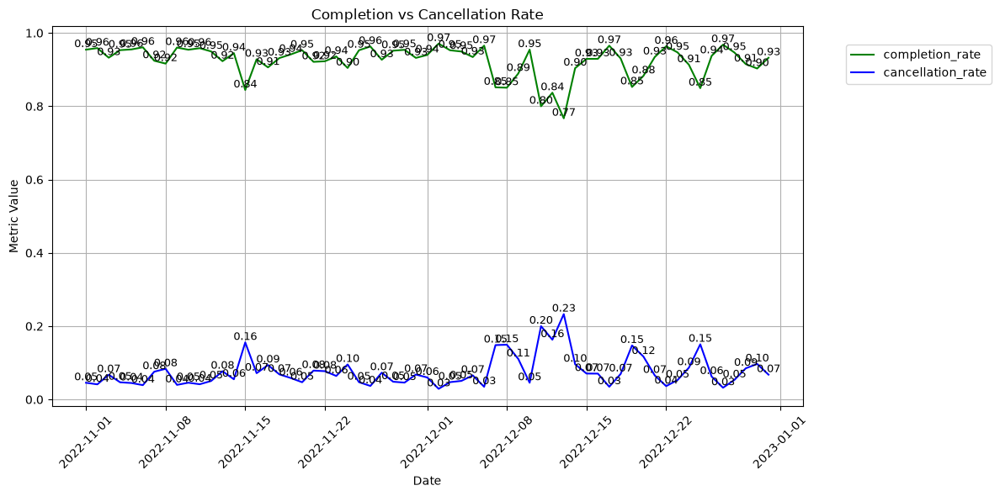

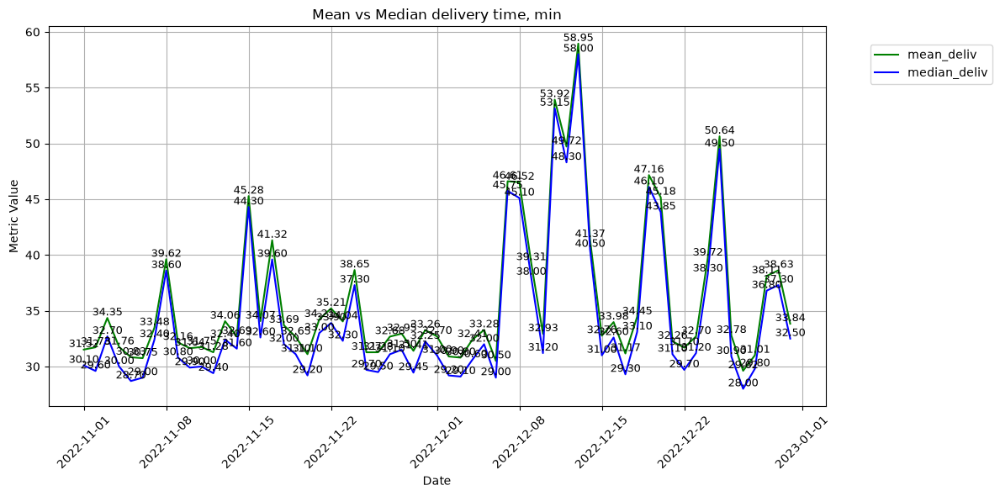

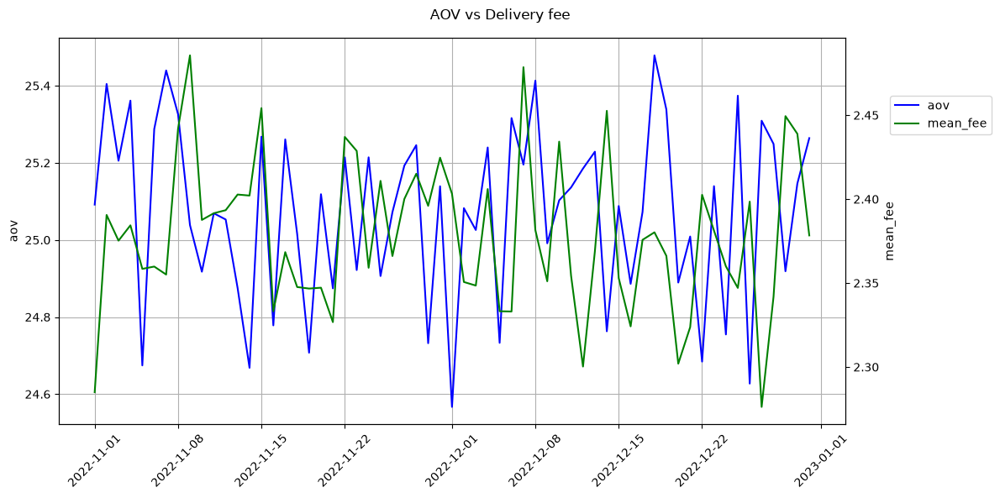

In [140]:
df['order_time'] = pd.to_datetime(df['order_time'])
df['delivery_time'] = pd.to_datetime(df['delivery_time'])
df['date'] = df['order_time'].dt.normalize()
df['delivery_min'] = (df['delivery_time'] - df['order_time']).dt.total_seconds() / 60

daily = df.groupby('date').agg(
    orders       = ('order_id', 'count'),
    delivered    = ('status', lambda s: (s == 'delivered').sum()),
    cancelled    = ('status', lambda s: (s == 'cancelled').sum()),
    mean_deliv   = ('delivery_min', 'mean'),
    median_deliv = ('delivery_min', 'median'),
    aov          = ('order_value', 'mean'),
    mean_fee     = ('delivery_fee', 'mean'),
).reset_index()

daily['completion_rate']   = daily['delivered'] / daily['orders']
daily['cancellation_rate'] = daily['cancelled'] / daily['orders']

get_several_lines_plot(daily, 'date', ['orders', 'delivered'],
                       'Orders vs Delivered orders')

get_several_lines_plot(daily, 'date', ['completion_rate', 'cancellation_rate'],
                       'Completion vs Cancellation Rate')

get_several_lines_plot(daily, 'date', ['mean_deliv', 'median_deliv'],
                       'Mean vs Median delivery time, min')

get_line_plot(daily, 'date', ['aov', 'mean_fee'],
              'AOV vs Delivery fee')

In [83]:
daily

,date,orders,delivered,cancelled,mean_deliv,median_deliv,aov,mean_fee
0,2022-11-01,1009,963,46,31.517445,30.1,25.091615,2.284965
1,2022-11-02,993,952,41,31.725630,29.6,25.404552,2.390564
2,2022-11-03,992,925,67,34.353622,32.7,25.205383,2.375252
3,2022-11-04,1535,1463,72,31.755707,30.0,25.361316,2.384384
4,2022-11-05,1514,1446,68,30.828907,28.7,24.674485,2.358448
...,...,...,...,...,...,...,...,...
56,2022-12-27,1092,1057,35,29.617219,28.0,25.309231,2.276209
57,2022-12-28,1049,993,56,31.005841,29.8,25.248961,2.341916
58,2022-12-29,941,861,80,38.114866,36.8,24.918778,2.449437
59,2022-12-30,1443,1303,140,38.629010,37.3,25.146376,2.438884


### Выраженного тренда нет

### Есть сильная недельная сезонность: в пятницу, субботу и воскресенье около 1500 заказов, в будни это ~1000

### В декабре сильно вырос cancellation_rate (с ~0.7 до 0.23 моментами)

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

In [87]:
def get_stl_results(df, x, metric, period=7):
    ts = df.set_index(x)[metric]
    stl = STL(ts, period=period, robust=True)
    stl_result = stl.fit()

    return stl_result

def get_stl_viz(stl_result, metric):
    trend = stl_result.trend
    seasonal = stl_result.seasonal
    resid = stl_result.resid
    observed = stl_result.observed

    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
    
    axes[0].plot(observed, label='Observed')
    axes[0].legend(loc='upper left')
    
    axes[1].plot(trend, color='orange', label='Trend')
    axes[1].legend(loc='upper left')
    
    axes[2].plot(seasonal, color='green', label='Seasonal')
    axes[2].legend(loc='upper left')
    
    axes[3].plot(resid, color='red', label='Residuals')
    axes[3].legend(loc='upper left')

    fig.suptitle(f'{metric} STL', fontsize=14)
    plt.tight_layout()
    plt.show()

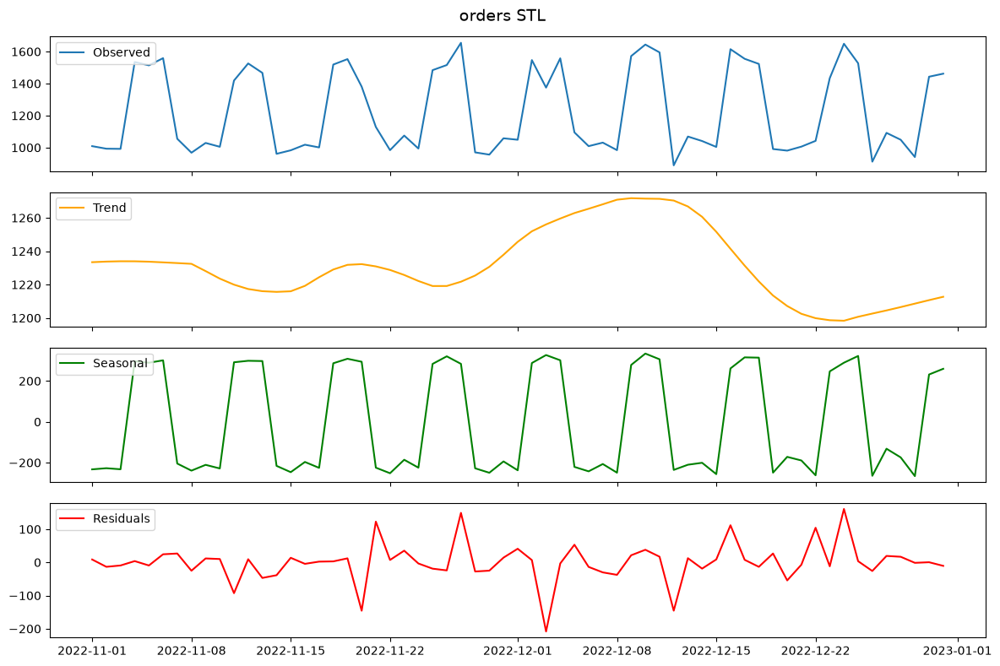

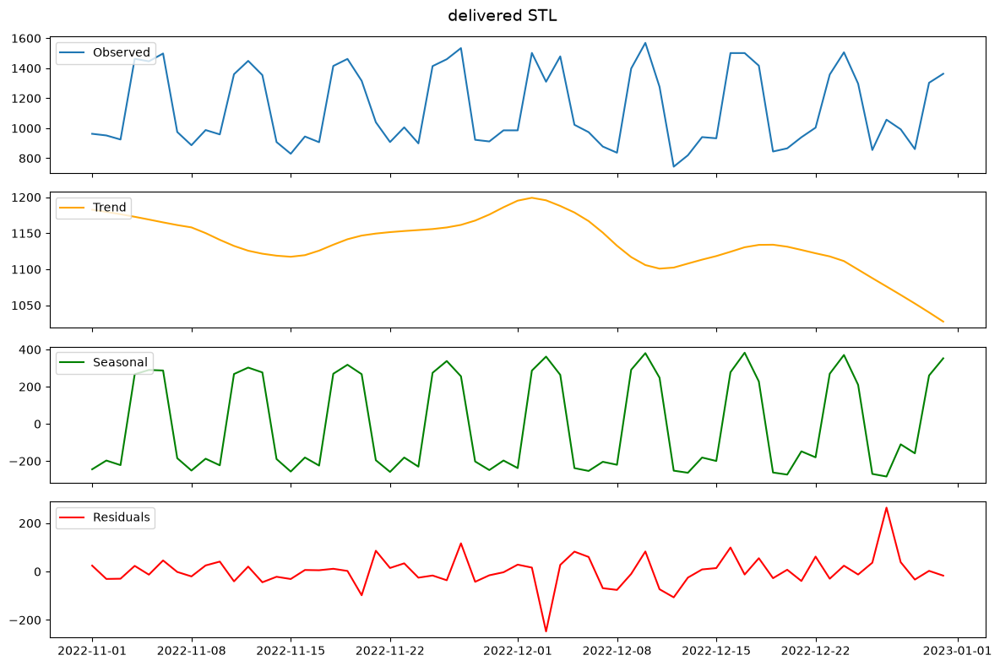

In [142]:
for metric in ['orders', 'delivered']:
    stl_res = get_stl_results(daily, 'date', metric)
    get_stl_viz(stl_res, metric)
    daily[f'{metric}_resid'] = stl_res.resid.values

In [91]:
def get_3sigma_vis(df, x, metric, control=True):
    plt.figure(figsize=(12,6))

    plt.plot(df[x], df[metric], marker='o', label=metric)

    if control:
        plt.plot(df[x], df[f'{metric}_ucl'], label=f'{metric}_ucl')
        plt.plot(df[x], df[f'{metric}_lcl'], label=f'{metric}_lcl')
    
    plt.scatter(df[df[f'is_anomaly_{metric}']][x],
                df[df[f'is_anomaly_{metric}']][metric],
                color='red', s=60, zorder=3, label='anomaly')
    
    for x_val, y_val in zip(df[x], df[metric]):
        plt.text(x_val, y_val + 0.005, f'{y_val:.2f}', fontsize=8, ha='center', va='bottom')
    
    plt.title(f'{metric.capitalize()} Dynamics')
    plt.xlabel(x)
    plt.xticks(ticks=df.date, labels=df.date.astype(str), rotation=45, ha='right', rotation_mode='anchor')
    plt.ylabel(metric)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    
def get_3_sigma_resid(df, metric, sigma=3):
    df[f'{metric}_mean'] = df[metric].mean()
    df[f'{metric}_ssd'] = df[metric].std(ddof=1)

    df[f'{metric}_ucl'] = df[f'{metric}_mean'] + sigma*df[f'{metric}_ssd']
    df[f'{metric}_lcl'] = df[f'{metric}_mean'] - sigma*df[f'{metric}_ssd']

    df[f'is_anomaly_{metric}'] = (df[metric] < df[f'{metric}_lcl']) | (df[metric] > df[f'{metric}_ucl'])

    return df

In [93]:
df_stl_3sigma_august = get_3_sigma_resid(daily, metric, sigma=3)

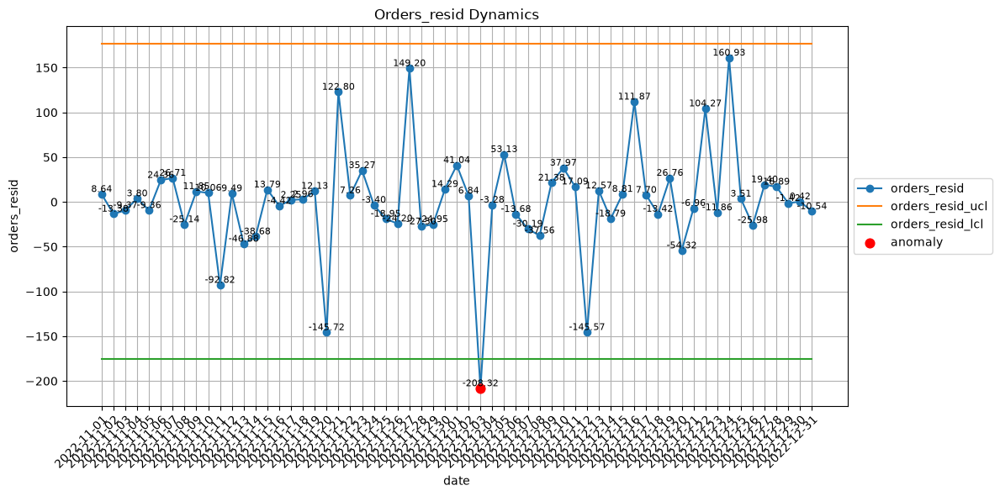

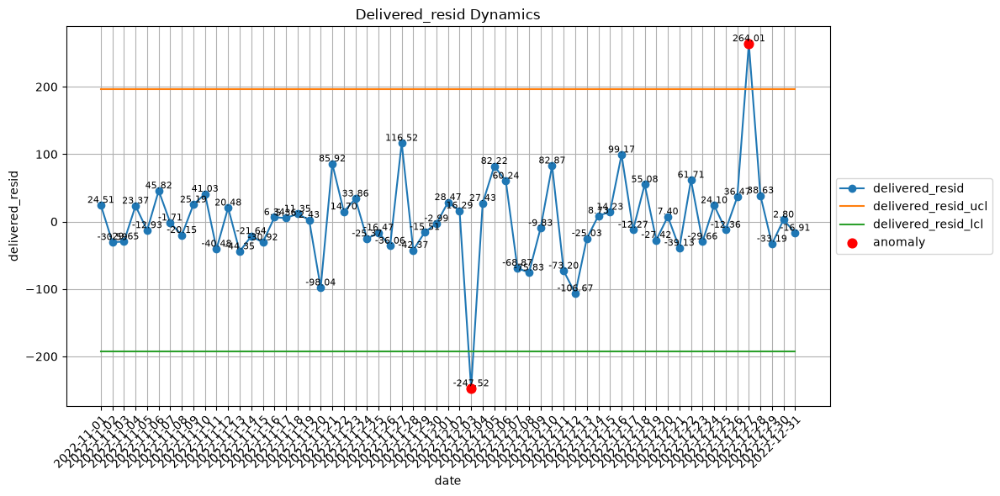

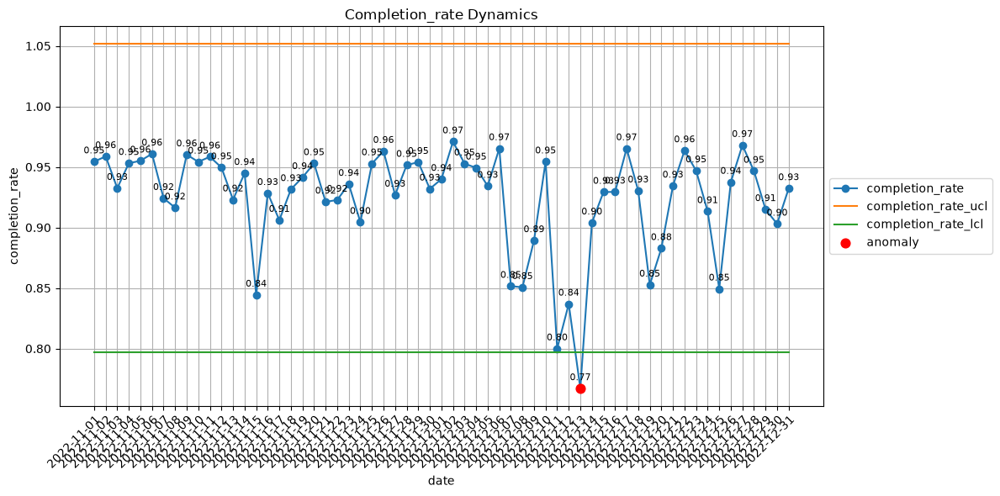

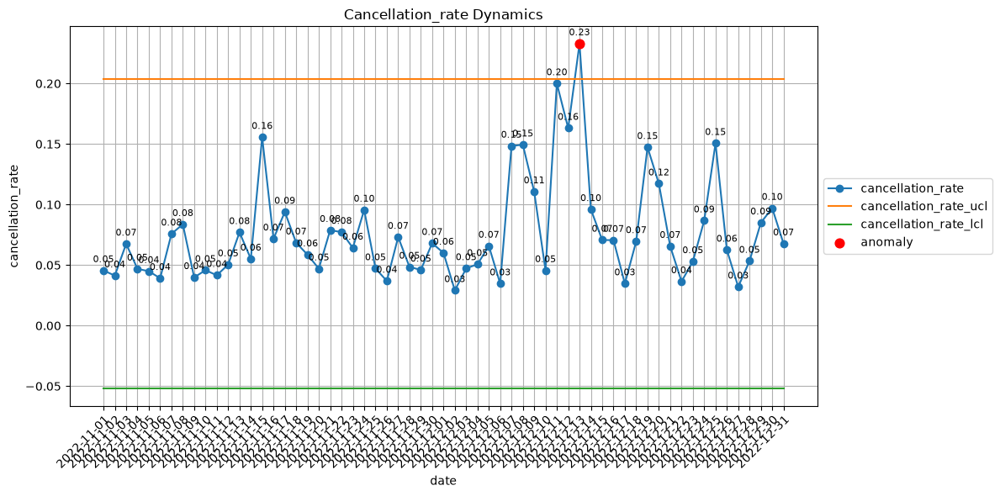

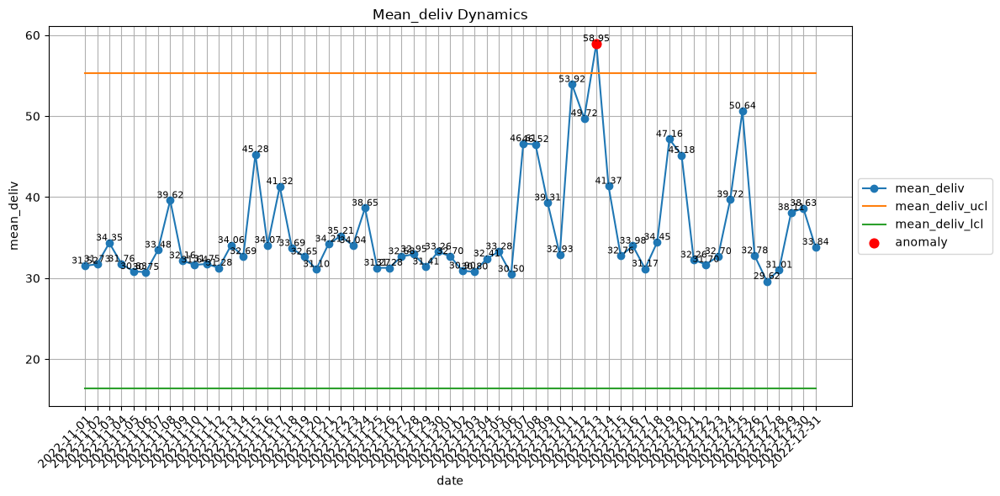

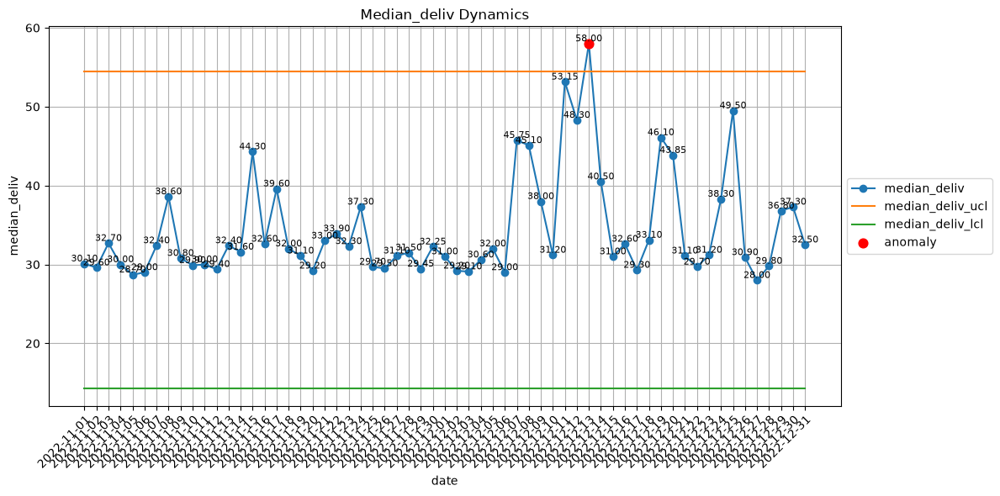

In [144]:
for metric in ['orders', 'delivered']:
    daily = get_3_sigma_resid(daily, f'{metric}_resid', sigma=3)
    get_3sigma_vis(daily, 'date', f'{metric}_resid')

for metric in ['completion_rate', 'cancellation_rate',
               'mean_deliv', 'median_deliv']:
    daily = get_3_sigma_resid(daily, metric, sigma=3)
    get_3sigma_vis(daily, 'date', metric)

In [130]:
cancel_daily

cancellation_reason,date,Cancelled by user,No courier available
0,2022-11-01,38,8
1,2022-11-02,35,6
2,2022-11-03,55,12
3,2022-11-04,58,14
4,2022-11-05,62,6
...,...,...,...
56,2022-12-27,34,1
57,2022-12-28,45,11
58,2022-12-29,56,24
59,2022-12-30,101,39


### В числе заказов и доставленных заказов после удаления недельной сезонности и тренда аномалий нет, но 13.12 - Cancellation rate 23%, Completion rate 0.77, среднее время доставки около 59 минут, медианное время доставки 58 мин

### в декабре регулярно бывают дни с ростом отмен и задержек при нормальном спросе.

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

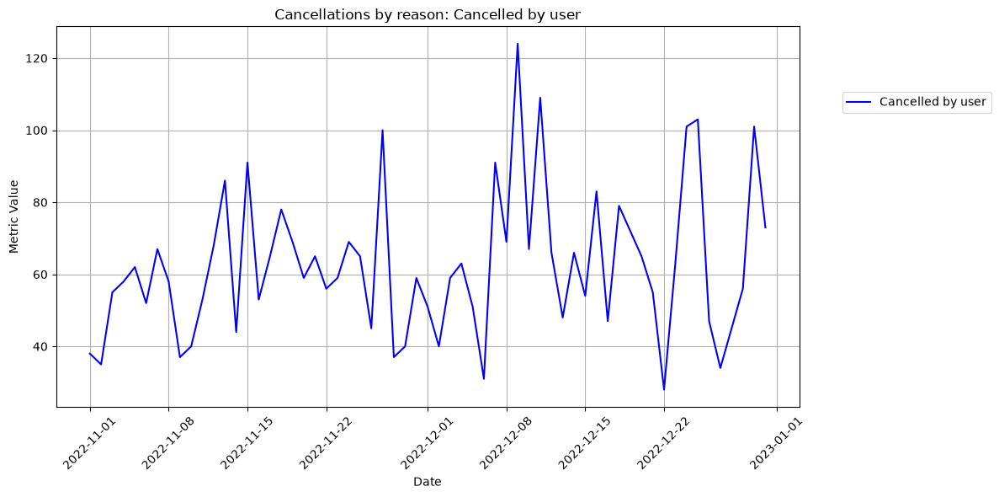

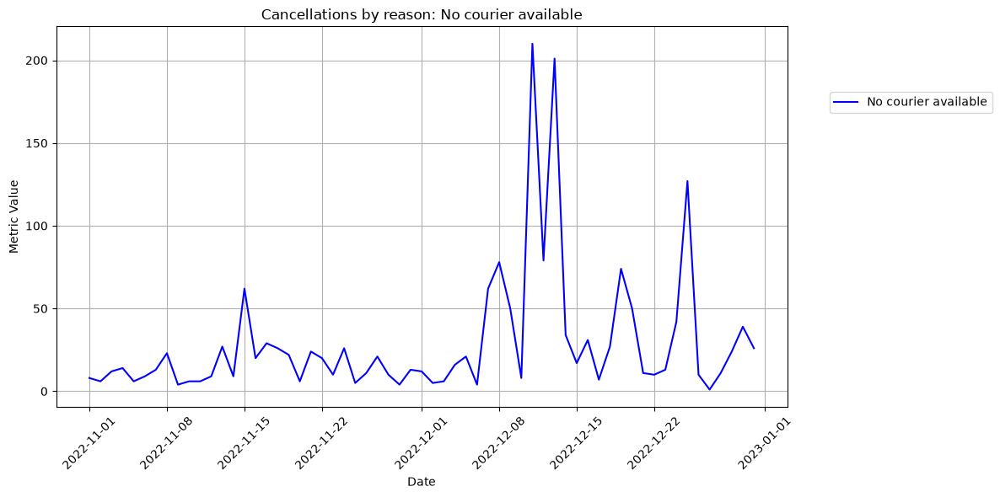

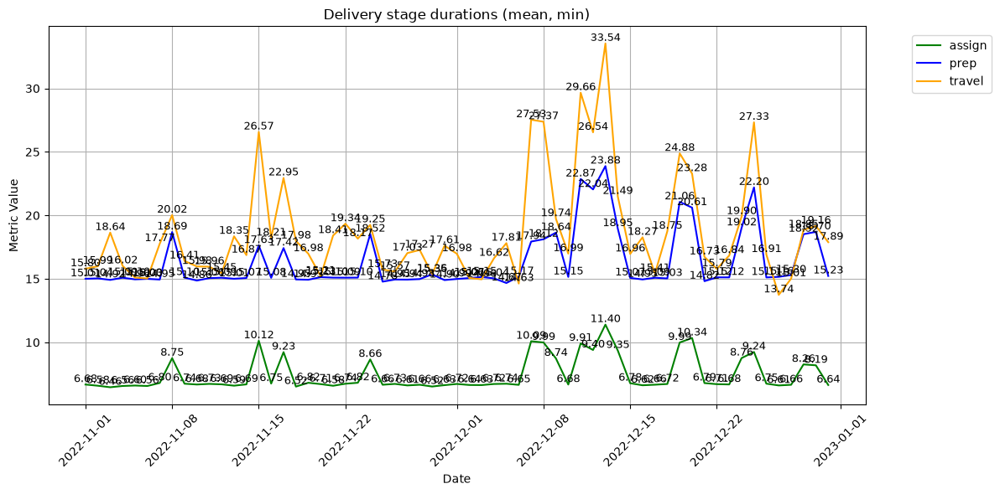

In [138]:
cancel_daily = (df[df['status'] == 'cancelled'].groupby(['date', 'cancellation_reason']).size().unstack(fill_value=0).reset_index())

for col in ['Cancelled by user', 'No courier available']:
    get_line_plot(cancel_daily, 'date', [col], f'Cancellations by reason: {col}')
    
stages = df.groupby('date').agg(
    assign = ('time_to_assign_courier_min', 'mean'),
    prep   = ('actual_preparation_time_min', 'mean'),
    travel = ('travel_time_min', 'mean'),
).reset_index()

get_several_lines_plot(stages, 'date', ['assign', 'prep', 'travel'], 'Delivery stage durations (mean, min)')

#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые / повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

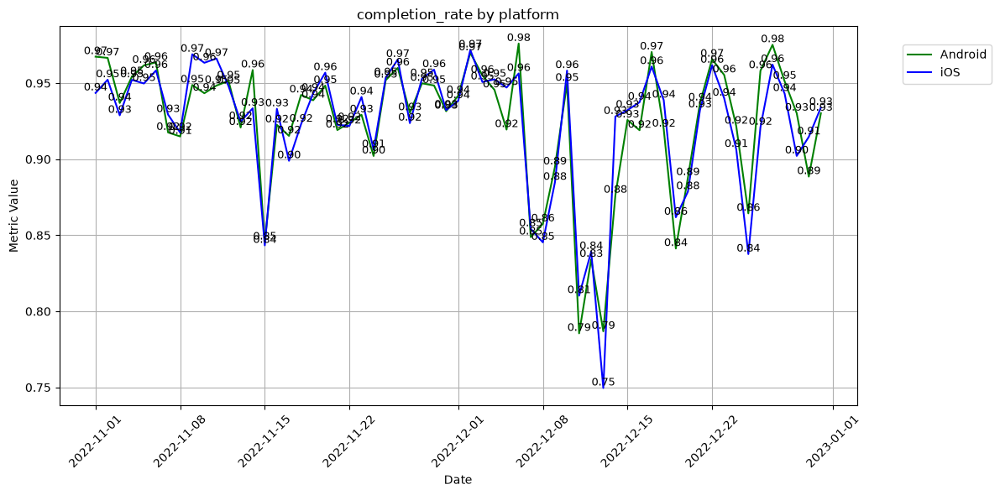

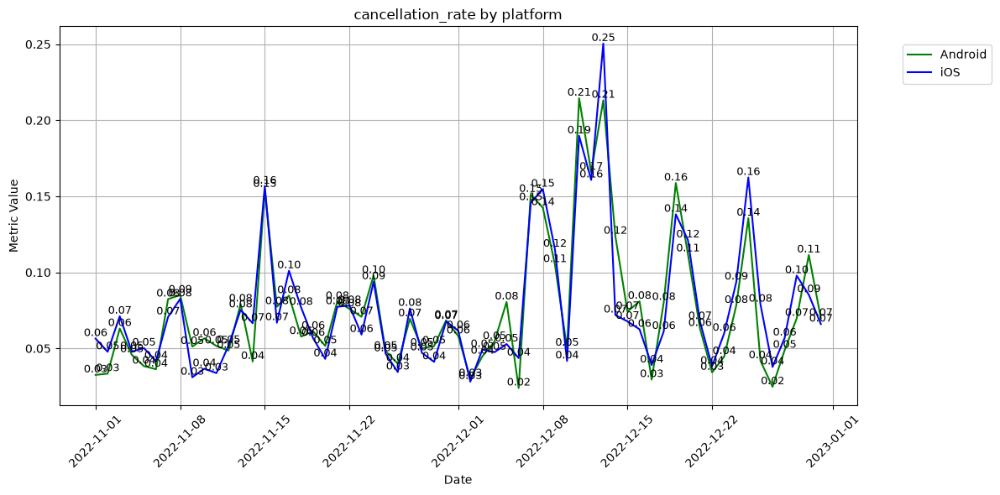

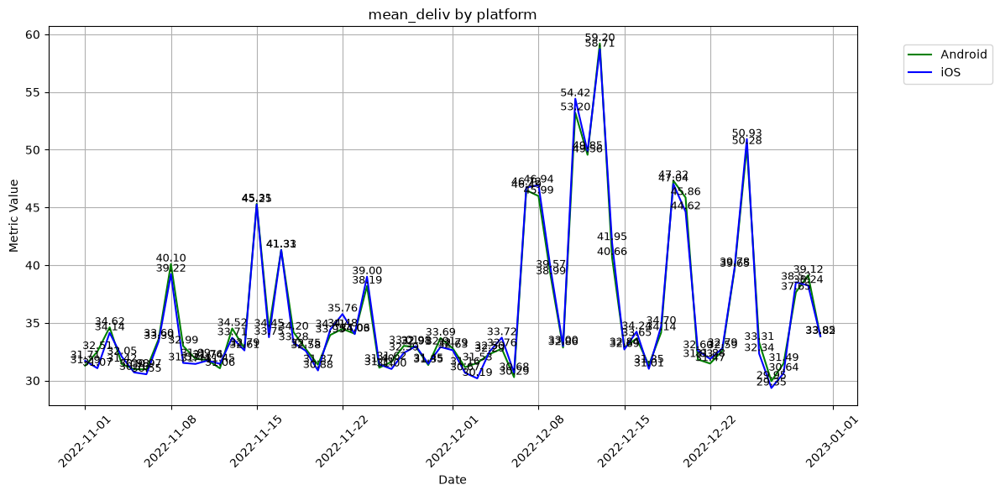

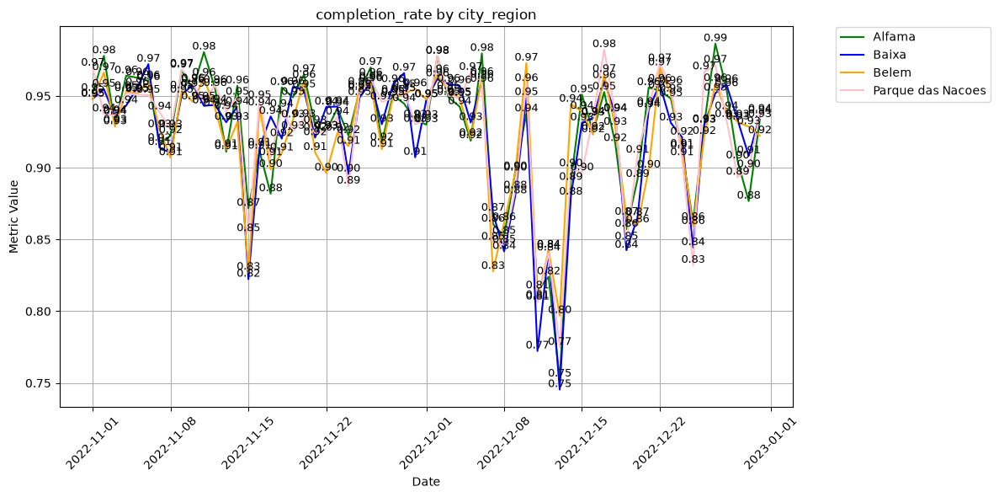

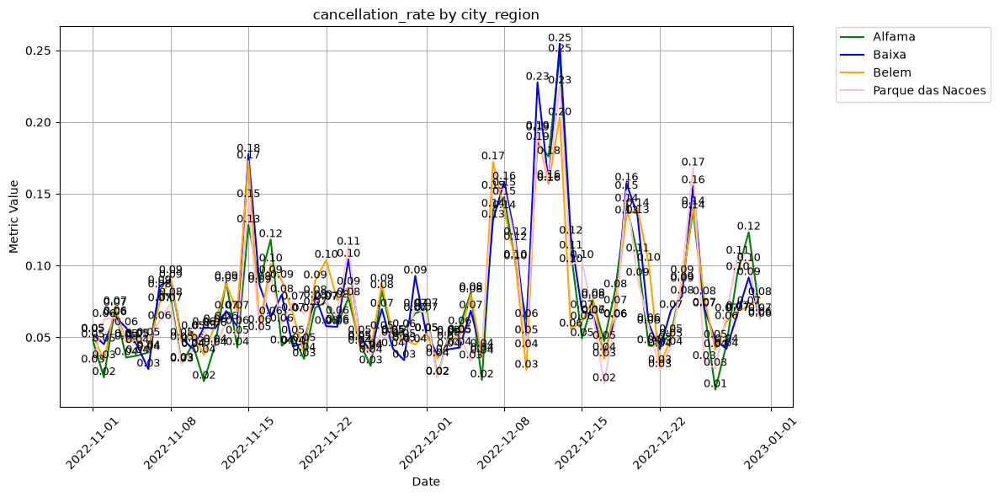

...

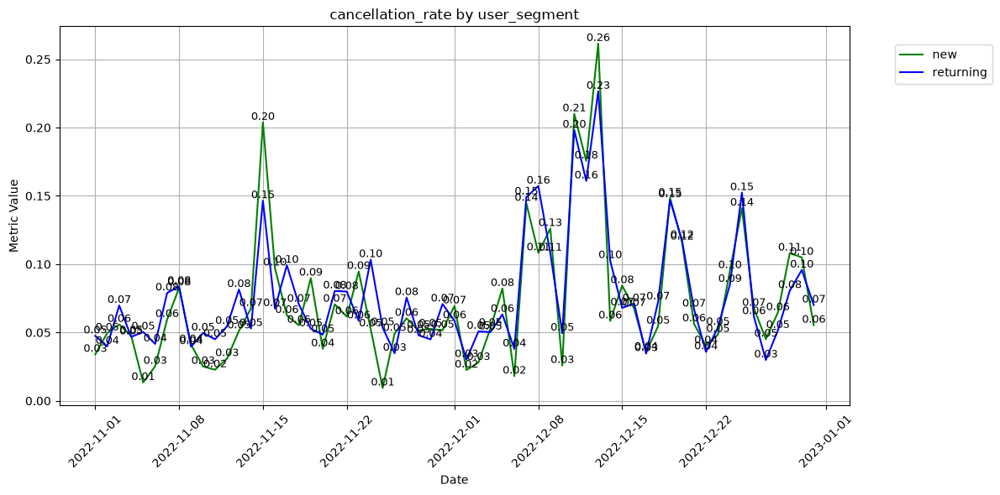

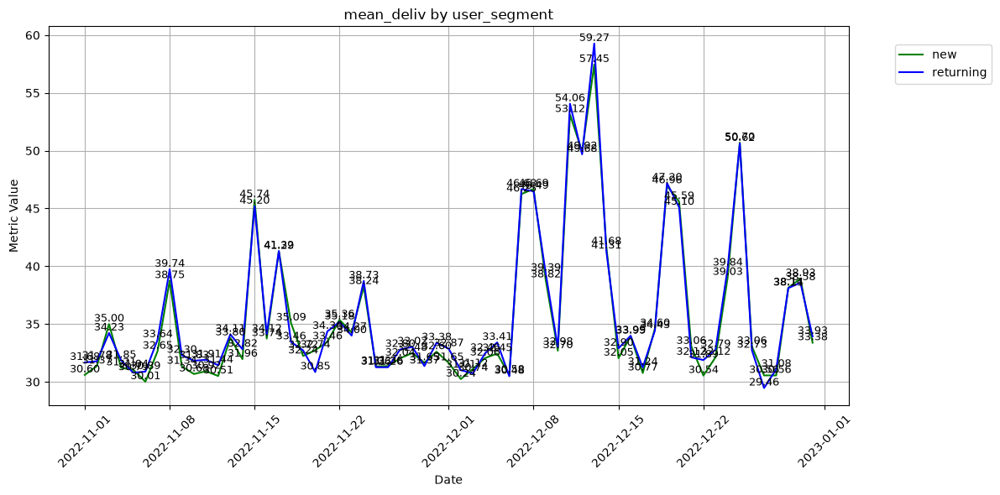

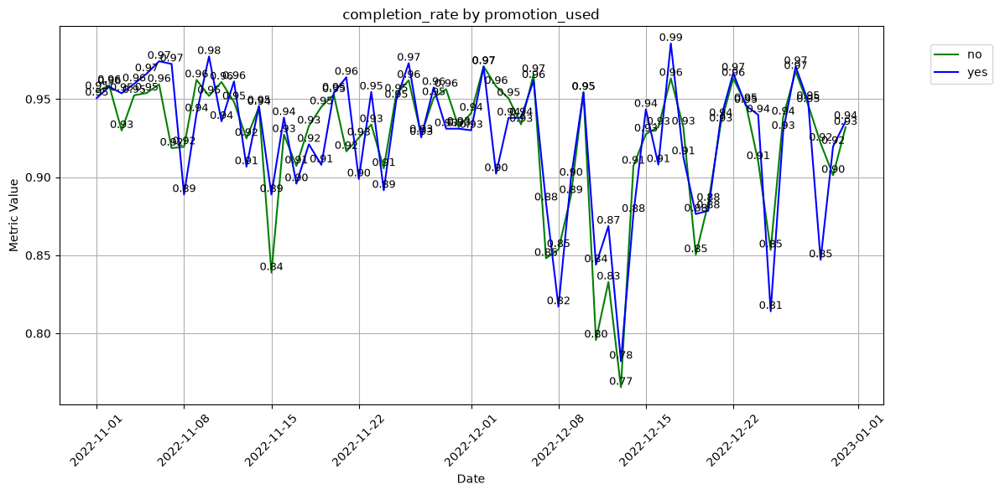

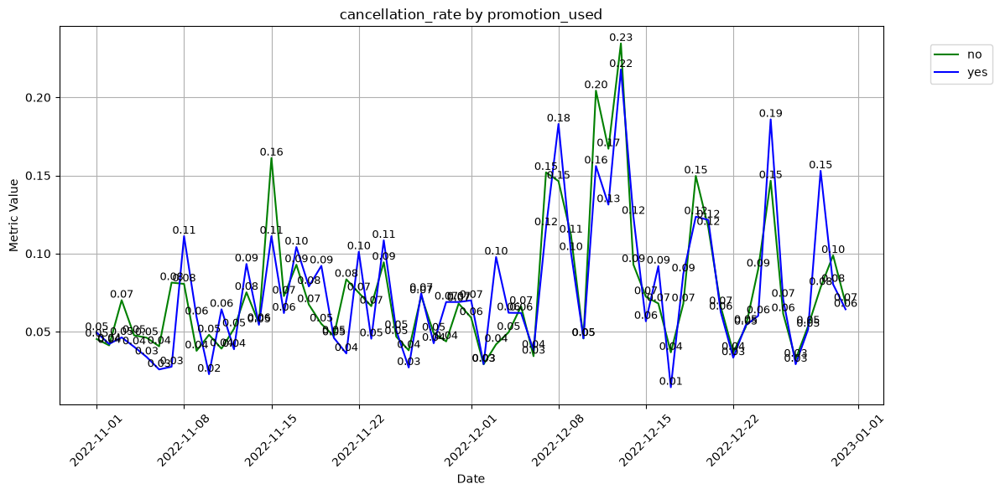

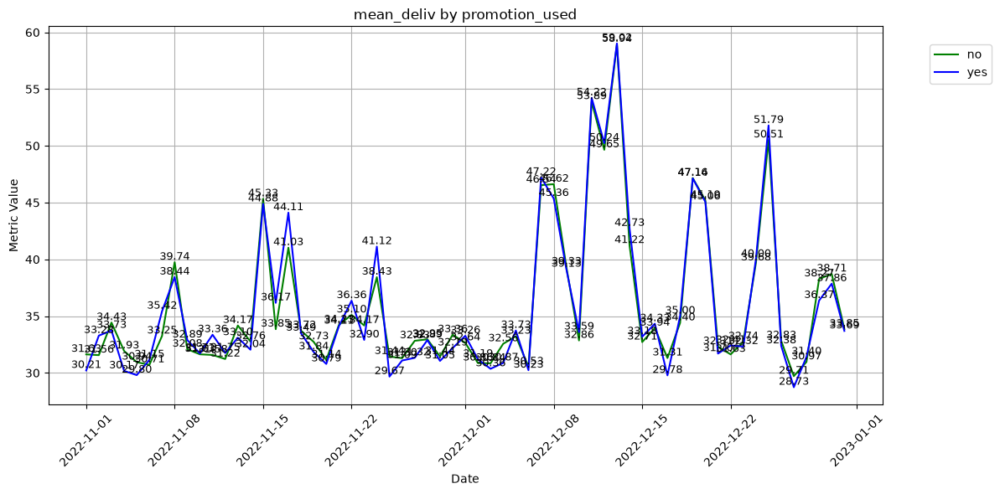

In [161]:
df['cancelled'] = (df['status'] == 'cancelled').astype(int)
segment_cols = ['platform', 'city_region', 'user_segment', 'promotion_used']

for segment in segment_cols:
    seg_daily = (df.groupby(['date',segment]).agg(
        orders      = ('order_id', 'count'),
        delivered   = ('status', lambda s: (s == 'delivered').sum()),
        cancelled   = ('cancelled', 'sum'),
        mean_deliv  = ('delivery_min', 'mean'))
    .reset_index()
    )
    seg_daily['completion_rate']   = seg_daily['delivered'] / seg_daily['orders']
    seg_daily['cancellation_rate'] = seg_daily['cancelled'] / seg_daily['orders']

    for metric in ['completion_rate', 'cancellation_rate', 'mean_deliv']:
        pivot = (seg_daily.pivot(index='date', columns=segment, values=metric).sort_index().reset_index())
        
        get_several_lines_plot(pivot, 'date', [c for c in pivot.columns if c != 'date'],f'{metric} by {segment}')

### ни один сегмент не выделяется. 

### во всех срезах линии на графиках почти совпадают, и пики отмен и времени доставки приходятся на одни и те же дни

### В плохие дни Cancellation Rate растёт примерно с 6% до 15-18%, а время доставки примерно с 33 до 49-50 минут одинаково во всех сегментах

### проблема не связана с конкретной платформой, районом или типом пользователя, нужно копать глубже

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

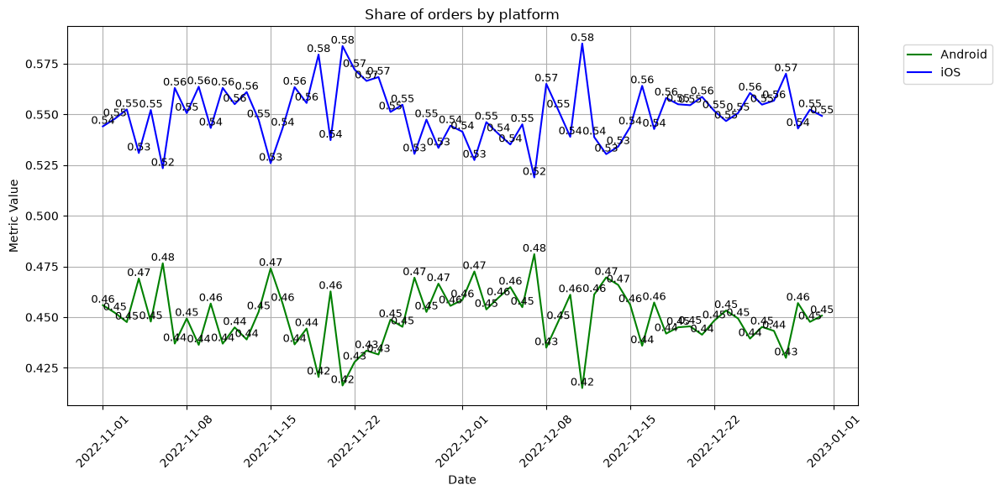

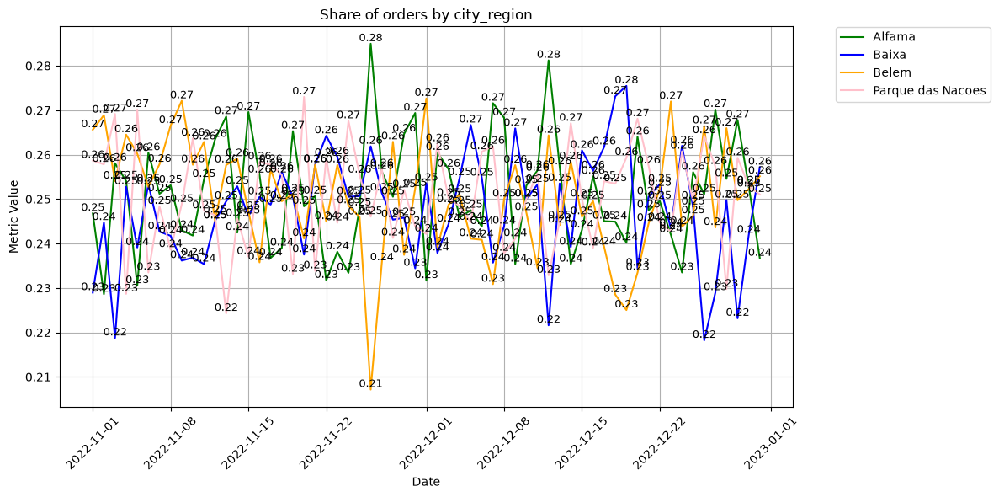

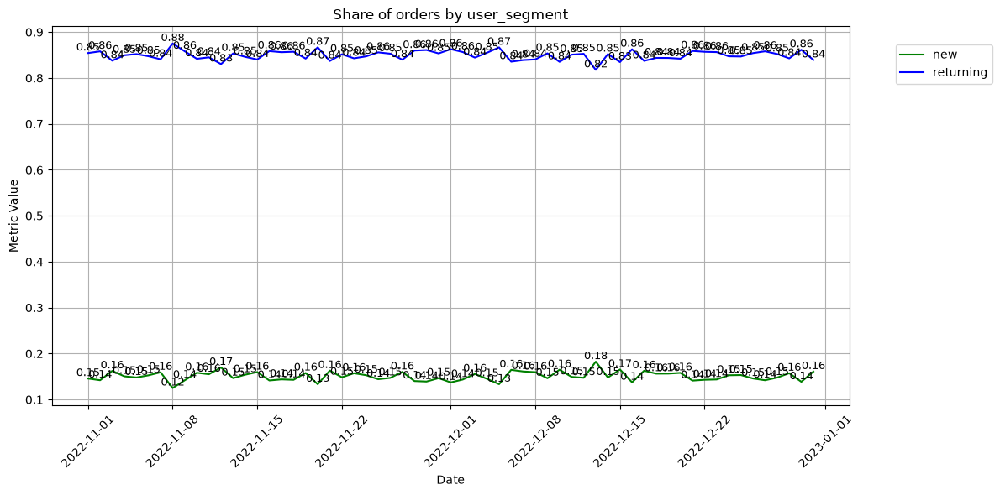

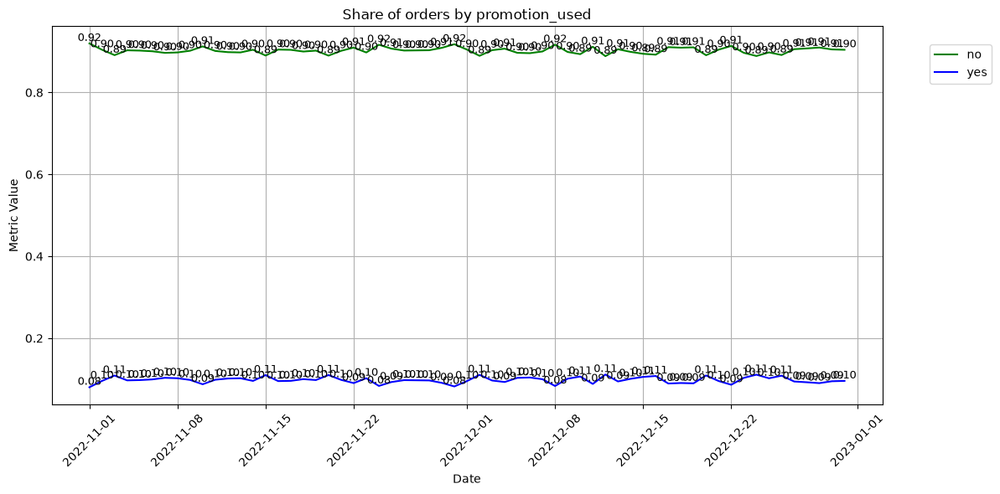

In [164]:
for col in segment_cols:
    counts = df.groupby(['date', col]).size().unstack(fill_value=0).sort_index()
    shares = counts.div(counts.sum(axis=1), axis=0).reset_index()

    get_several_lines_plot(
        shares, 'date',
        [c for c in shares.columns if c != 'date'],
        f'Share of orders by {col}'
    )

### структура заказов весь период стабильна

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [167]:
start_date = daily['date'].min().strftime('%Y-%m-%d')
end_date = daily['date'].max().strftime('%Y-%m-%d')

url = 'https://archive-api.open-meteo.com/v1/archive'

params = {
    'latitude': 38.736946,
    'longitude': -9.142685,
    'start_date': start_date,
    'end_date': end_date,
    'daily': 'temperature_2m_mean,precipitation_sum,wind_speed_10m_max',
    'timezone': 'auto'
}

resp = requests.get(url, params=params)
resp.raise_for_status()
weather_json = resp.json()

weather = pd.DataFrame({
    'date': pd.to_datetime(weather_json['daily']['time']),
    'temperature_2m_mean': weather_json['daily']['temperature_2m_mean'],
    'precipitation_sum': weather_json['daily']['precipitation_sum'],
    'wind_speed_10m_max': weather_json['daily']['wind_speed_10m_max']
})

weather.head()

,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,2022-11-01,15.7,0.0,16.1
1,2022-11-02,14.8,0.0,14.8
2,2022-11-03,17.7,4.2,23.1
3,2022-11-04,15.6,0.0,15.5
4,2022-11-05,14.1,0.0,9.7


#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

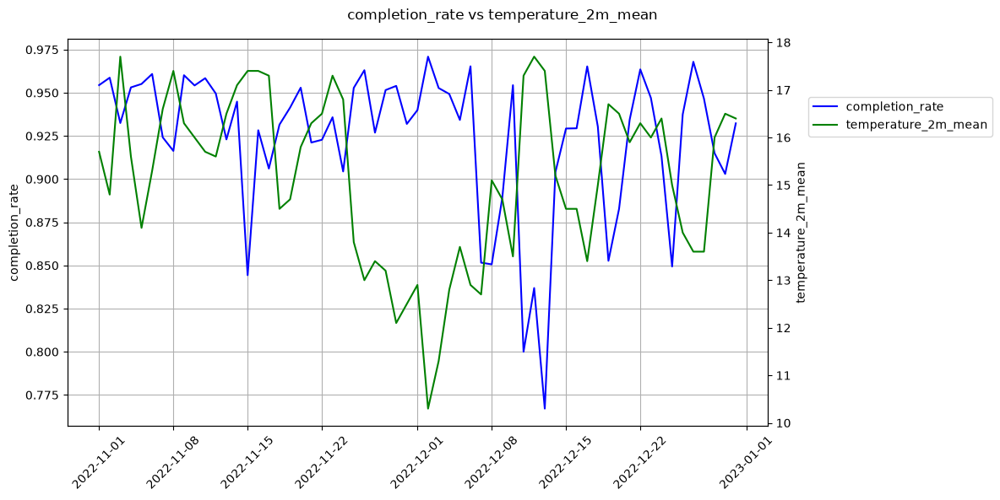

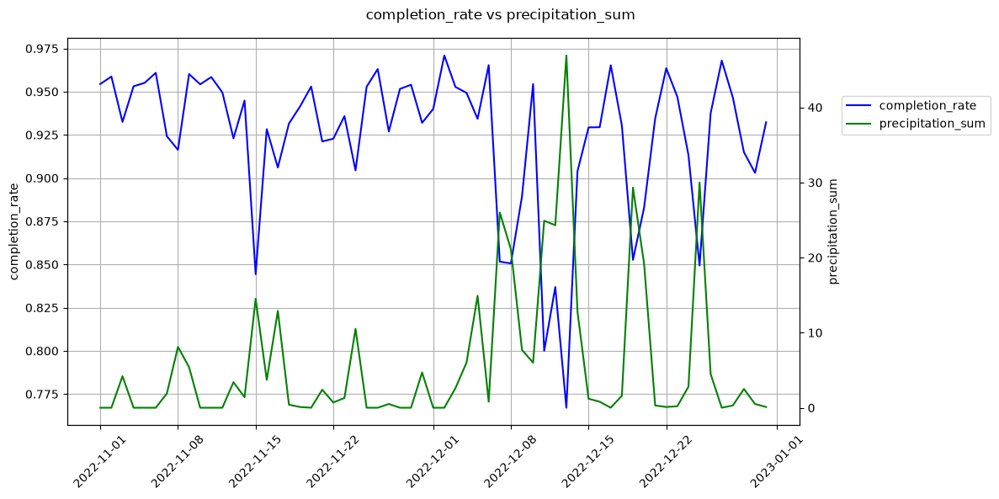

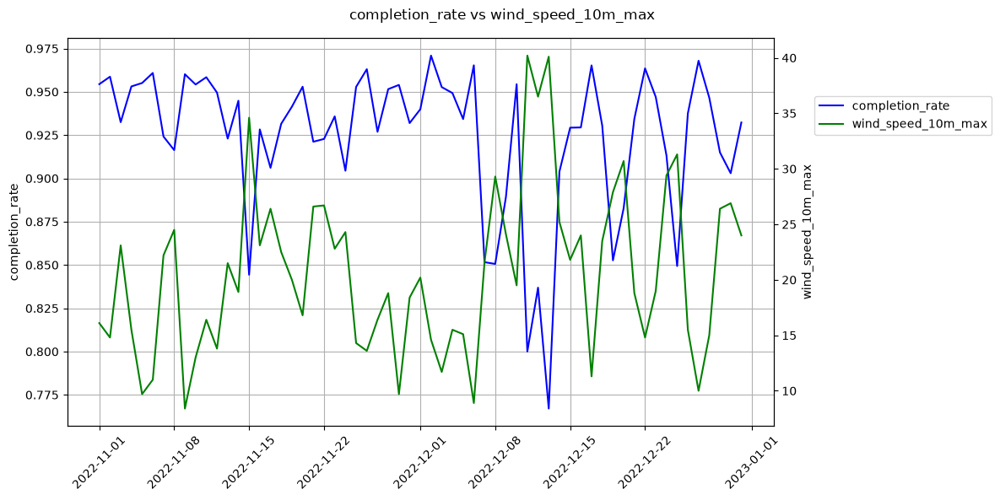

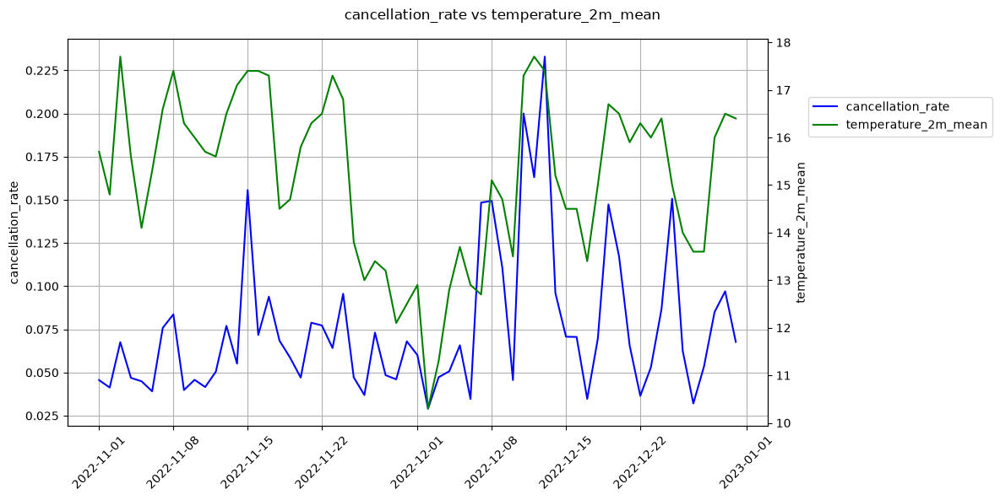

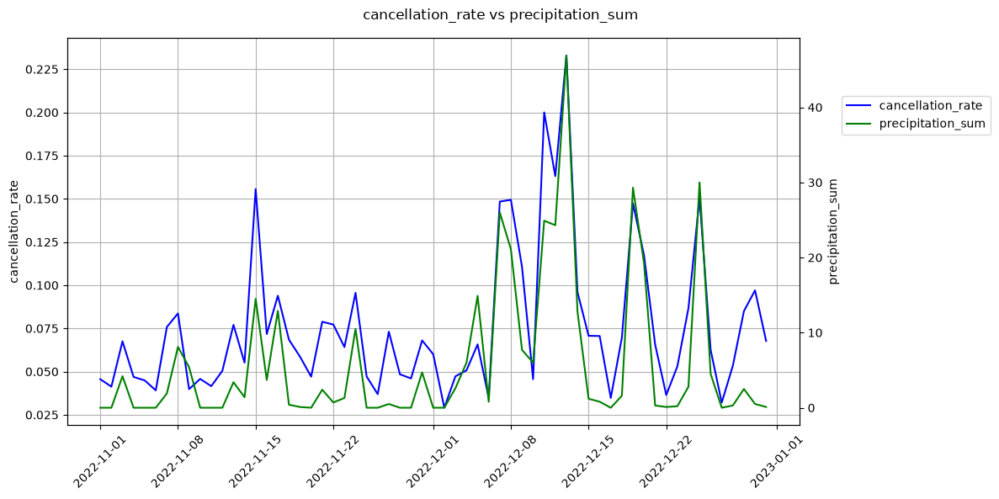

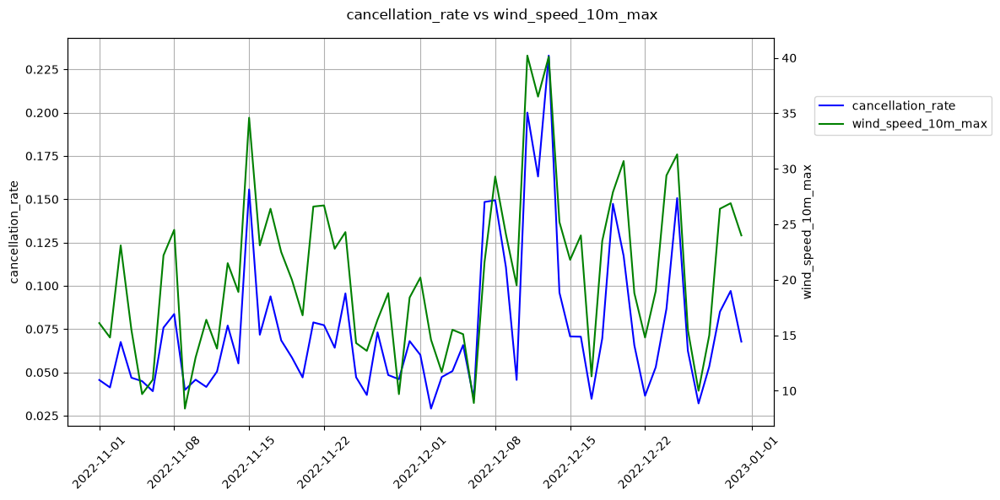

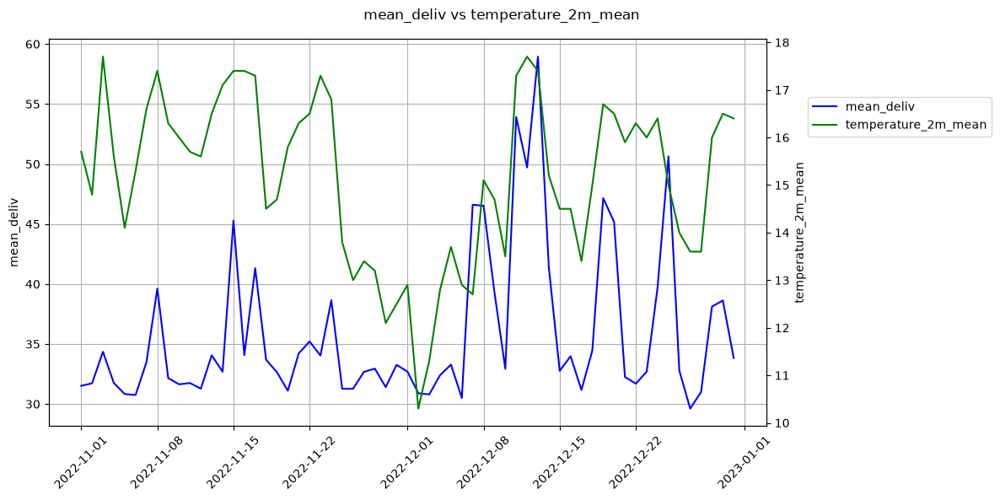

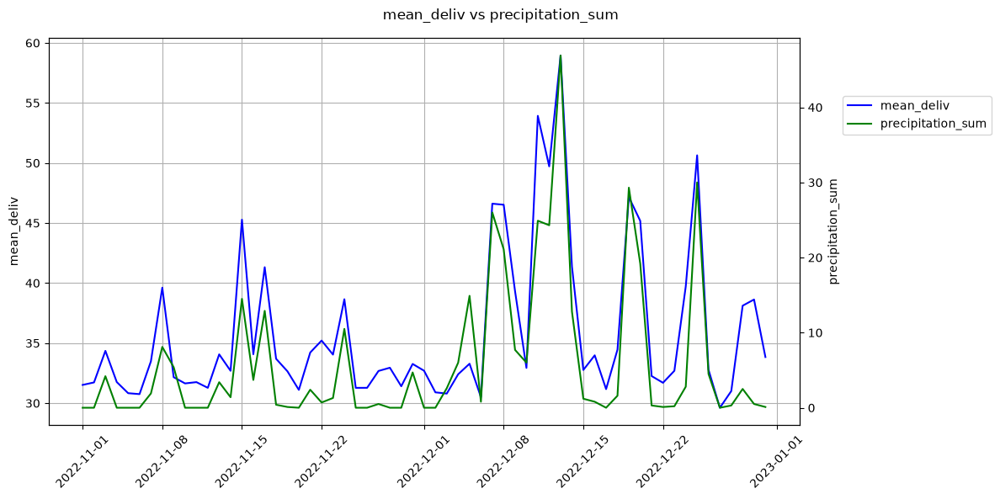

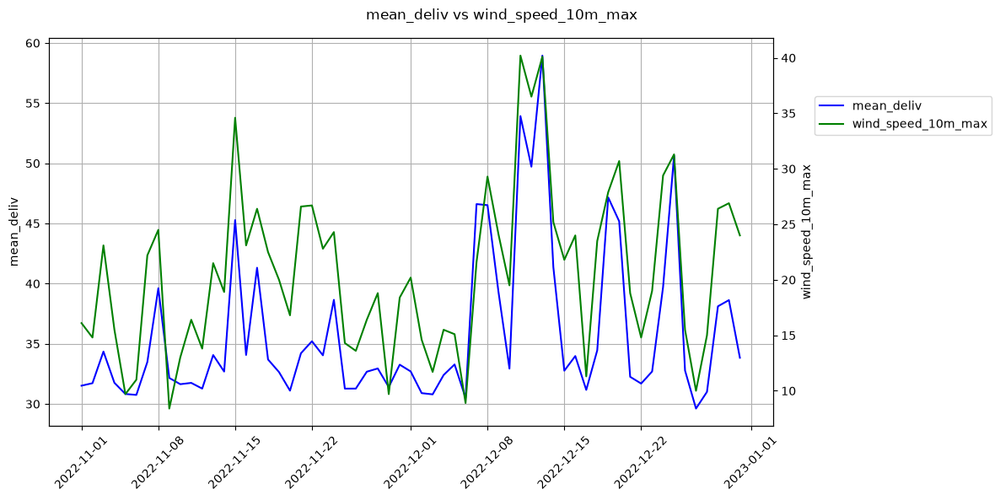

In [219]:
def get_stl_3sigma_anomalies(series, period, robust = True):
    stl = STL(series, period=period, robust=robust)
    result = stl.fit()
    residual = result.resid
    mu = residual.mean()
    sigma = residual.std()

    lower_bound = mu - 3 * sigma
    upper_bound = mu + 3 * sigma
    df_anomalies = pd.DataFrame(
        {
            "observed": series,
            "trend": result.trend,
            "seasonal": result.seasonal,
            "residual": residual,
            "is_anomaly": (residual < lower_bound) | (residual > upper_bound),
        }
    )

    return df_anomalies
    
analysis = daily.copy()

for metric in ['orders', 'delivered']:
    ts = analysis.set_index('date')[metric]                      
    stl_res = get_stl_3sigma_anomalies(ts, period=7, robust=True) 
    analysis[f'{metric}_resid']      = stl_res['residual'].values
    analysis[f'is_anomaly_{metric}'] = stl_res['is_anomaly'].values

for metric in ['completion_rate', 'cancellation_rate', 'mean_deliv', 'median_deliv']:
    analysis = get_3_sigma_resid(analysis, metric)

analysis = analysis.merge(weather, on='date', how='left')

analysis.head()

weather_cols = ['temperature_2m_mean', 'precipitation_sum', 'wind_speed_10m_max']
metric_cols  = ['completion_rate', 'cancellation_rate', 'mean_deliv']

for metric in metric_cols:
    for w in weather_cols:
        get_line_plot(analysis, 'date', [metric, w],
                      f'{metric} vs {w}')

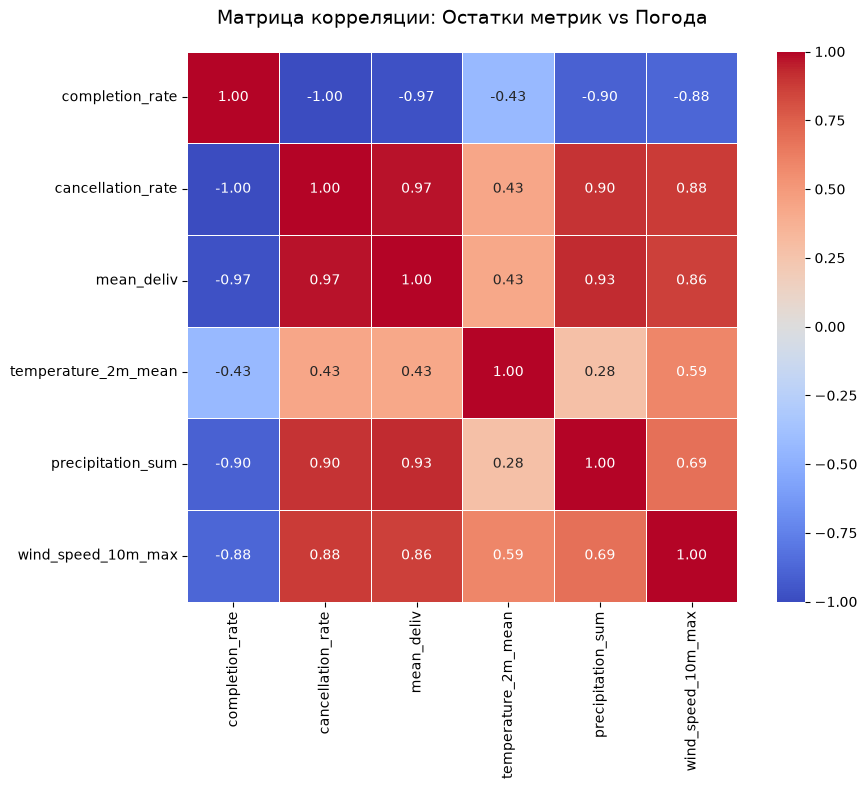

In [225]:
corr_cols = metric_cols + weather_cols

corr_matrix = analysis[corr_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5, square=True)

plt.title('Матрица корреляции: Остатки метрик vs Погода', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### падение конверсии в доставку в дни аномалий вызвано сильными дождями и ветром

### Все дни с аномалиями совпадают с днями, когда осадков больше ~10 мм и ветер сильнее ~25 км/ч 
### Корреляция Cancellation Rate и времени доставки с осадками и ветром  0.97. 
### С температурой связь умеренная

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам. 

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы / дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [200]:
daily['month'] = pd.to_datetime(daily['date']).dt.month
monthly = daily.groupby('month')[['orders', 'delivered']].sum()
monthly['cr'] = monthly['delivered'] / monthly['orders']

o1, o2 = monthly.loc[11, 'orders'], monthly.loc[12, 'orders']
cr1, cr2 = monthly.loc[11, 'cr'], monthly.loc[12, 'cr']
d1, d2 = monthly.loc[11, 'delivered'], monthly.loc[12, 'delivered']

orders_effect = (o2 - o1) * cr1
cr_effect = o2 * (cr2 - cr1)

monthly

,orders,delivered,cr
month,,,
11,36308,34084,0.938746
12,38684,35337,0.913478


In [203]:
orders_effect

2230.461165583343

In [205]:
cr_effect

-977.4611655833456

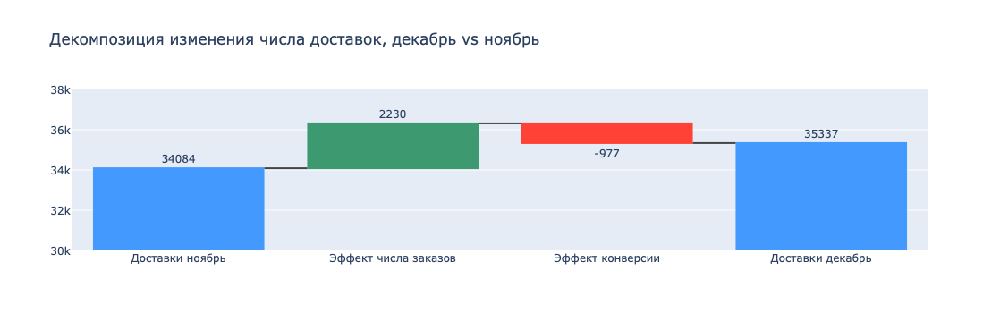

In [208]:
fig = go.Figure(go.Waterfall(
    x=['Доставки ноябрь', 'Эффект числа заказов', 'Эффект конверсии', 'Доставки декабрь'],
    measure=['absolute', 'relative', 'relative', 'total'],
    y=[d1, orders_effect, cr_effect, d2],
    text=[d1, round(orders_effect), round(cr_effect), d2],
    textposition='outside'
))
fig.update_layout(title='Декомпозиция изменения числа доставок, декабрь vs ноябрь', yaxis_range=[30000, 38000])
fig.show()

In [228]:
dec = daily[daily['month'] == 12].copy()
dec['contribution'] = (dec['delivered'] - cr1 * dec['orders']) / o2
dec = dec.merge(weather, on='date')

dec.sort_values('contribution')[['date', 'orders', 'completion_rate', 'contribution', 'precipitation_sum', 'wind_speed_10m_max']].head(10)

,date,orders,completion_rate,contribution,precipitation_sum,wind_speed_10m_max
10,2022-12-11,1595,0.800000,-0.005721,24.9,40.2
12,2022-12-13,1069,0.767072,-0.004744,46.9,40.1
24,2022-12-25,1527,0.849378,-0.003528,30.0,31.3
11,2022-12-12,889,0.836895,-0.002341,24.3,36.5
6,2022-12-07,1031,0.851600,-0.002323,26.0,21.6
7,2022-12-08,984,0.850610,-0.002242,21.1,29.3
18,2022-12-19,991,0.852674,-0.002205,29.3,27.9
8,2022-12-09,1572,0.889313,-0.002009,7.7,24.1
19,2022-12-20,981,0.882773,-0.001419,19.2,30.7
29,2022-12-30,1443,0.902980,-0.001334,0.5,26.9


### число доставок в декабре выросло на 1253 по сравнению с ноябрём, но только за счёт роста числа заказов (+2372). Падение конверсии с 93.9% до 91.3% забрало около 977 доставок

####   10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.* 

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели / часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста: 
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

### свитчбек по 30-минутным окнам, так как поюзерно будет смещение от спроса той или иной когорты, а пул курьеров будет доставлять заказы быстрее / медленнее из-за меньшего или большего спроса 
### районов всего 4, это не подходит для случайного выбора, так как курьеры будут пермещаться между ними, смещая оценку


#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

### Completion Rate - основная метрика эксперимента, как указано в гипотезе. Вместе с ней будем смотреть на среднее время доставки

#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

### Доля отмен по причине No courier available — проверяет, что наценка не ухудшила доступность курьеров (если они не пришли — механизм гипотезы сломан)
### Средний чек - наценка не должна разрушать продуктовую корзину пользователя (снижение чека = отток платёжеспособных клиентов)
### Средний gross revenue на заказ  - прямой денежный риск: наценка может отпугнуть пользователей и уронить выручку

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

In [124]:
alpha_raw  = 0.05
beta       = 0.20
n_decision = 2      
alpha_adj  = alpha_raw / n_decision  

from scipy.stats import norm
z_alpha = norm.ppf(1 - alpha_adj/2)
z_beta  = norm.ppf(1 - beta)
print(f'alpha_adj={alpha_adj}, z_alpha={z_alpha:.3f}, z_beta={z_beta:.3f}')

alpha_adj=0.025, z_alpha=2.241, z_beta=0.842


#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях декабря полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении / исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [24]:
# your code is here

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных таргет и вторичной метрик принятия решений. 

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\; 
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X) 
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y) 
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

In [122]:
# your code is here

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта). 

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [123]:
# your code is here

#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [124]:
# your code is here

#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

In [125]:
# your answer is here